# Models

## Setup

In [1]:
import sys; sys.path.append("..")   # lets the notebook see src/
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
from src.data import load_clean
from src.features import build_preprocessor, split_xy
from src.evaluate import cv_report
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV, LassoCV, LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

df = load_clean()
X, y = split_xy(df)
prep = build_preprocessor()

## Model Comparison

In [2]:
alphas = np.logspace(-5, 2, 30)

models = {
    "mean baseline": DummyRegressor(strategy="mean"),
    "linear":        make_pipeline(prep, LinearRegression()),
    "ridge":         make_pipeline(prep, RidgeCV(alphas=alphas)),
    "lasso":         make_pipeline(prep, LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=9)),
    "gbm":           make_pipeline(prep, HistGradientBoostingRegressor(random_state=9)),
}

cv_report(models, X, y)

,r2,r2_std,rmse,mae
model,,,,
mean baseline,-0.0003,0.0002,3.2295,2.6815
linear,0.2739,0.0067,2.7516,2.2109
ridge,0.2739,0.0067,2.7516,2.2109
lasso,0.2739,0.0066,2.7516,2.2109
gbm,0.3024,0.0111,2.6969,2.1673


In [3]:
print("ridge alpha:", models["ridge"].fit(X, y)[-1].alpha_)
print("lasso alpha:", models["lasso"].fit(X, y)[-1].alpha_)

ridge alpha: 6.2101694189156165
lasso alpha: 0.0004893900918477494


All models beat the baseline, with linear, ridge and lasso all being identical and choosing negligible penalties (ridge alpha: 6.21 and lasso alpha: 0.000489). GBM improves $R^2$ by 0.03 over the linear models, which is a modest gain, that shows that a flexible model seems to find small non-linear structure, but not a lot. Since all scores are low, the problem lies in the features carrying limited signal about the interest rates, rather than with the models. Given the small gap, the linear model is the better choice for interpretation.

## Cutoff Sensitivity

In [4]:
results = {}
for age in (14, 16):
    X_age, y_age = split_xy(load_clean(min_work_age=age))
    model = make_pipeline(build_preprocessor(), LinearRegression())
    results[f"min_work_age={age}"] = cv_report({"linear": model}, X_age, y_age).loc["linear"]

pd.DataFrame(results).T

,r2,r2_std,rmse,mae
min_work_age=14,0.2739,0.0067,2.7516,2.2109
min_work_age=16,0.2738,0.0050,2.7495,2.2086


The two rules give identical performance within cross validation noise (ΔR² = 0.0001 vs fold std ≈ 0.006), so the suspicious age/employment length cluster carries no distinct signal. I will keep the legal floor of 14 and keep the rows.

## What the Linear Model Learned

In [5]:
linear = models["linear"].fit(X, y)
names = linear[0].get_feature_names_out()
coefs = (pd.Series(linear[-1].coef_, index=names)
           .sort_values(key=abs, ascending=False)
           .round(3))
coefs.to_frame("coefficient")

,coefficient
cat__cb_person_default_on_file_Y,4.128
cat__person_home_ownership_OTHER,0.998
cat__person_home_ownership_RENT,0.726
cat__person_home_ownership_OWN,0.337
log__loan_amnt,0.202
num__loan_percent_income,0.189
cat__loan_intent_HOMEIMPROVEMENT,0.171
num__person_emp_length,-0.084
num__cb_person_cred_hist_length,0.078
log__person_income,0.055


Dummy coefficients are in percentage points relative to the reference categories ( `MORTGAGE`,`DEBTCONSOLIDATION`, `N`) and numeric coefficients are per standard deviation. A prior default on file is by far the strongest feature, raising the rate by 4.1 points, as expected, since it leads to a higher risk for the lender. All home ownership categories (Rent, Own, Other) get higher rates than their reference category (Mortgage holders). The logged loan amount and loan to income add about 0.2 points per standard deviation. All other features are around ±0.1 and contribute with close to no effect. The model is essentially just default on file, with small adjustments. 

## Residuals

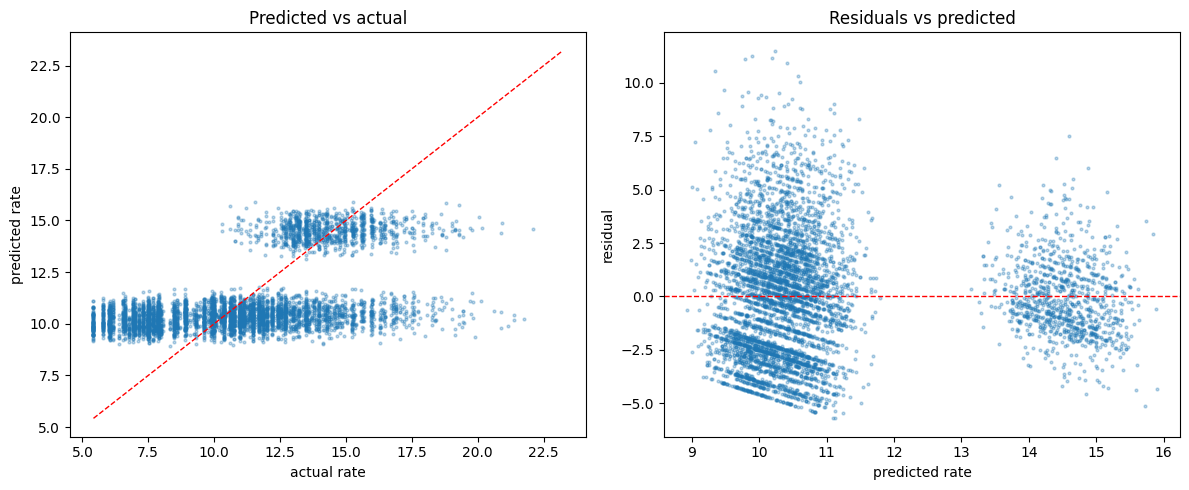

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=9)
pred = models["linear"].fit(X_tr, y_tr).predict(X_te)
resid = y_te - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_te, pred, s=4, alpha=0.3)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=1)
axes[0].set(xlabel="actual rate", ylabel="predicted rate", title="Predicted vs actual")

axes[1].scatter(pred, resid, s=4, alpha=0.3)
axes[1].axhline(0, color="r", ls="--", lw=1)
axes[1].set(xlabel="predicted rate", ylabel="residual", title="Residuals vs predicted")
plt.tight_layout()

Two clouds form in the predicted rates, around the 10 and 15 point mark. The actual rates range from 5 to 22 points, whereas the predictions stay close to each of the two clouds centers. These narrow vertical clouds reflect the low $R^2$-scores and show that the models aren't useful for prediction. As seen in the earlier analysis, the clouds likely stem from the dominant prior default on file feature. In the following cell I will color in the residuals by said feature.

Text(0.5, 1.0, 'Residuals by default on file')

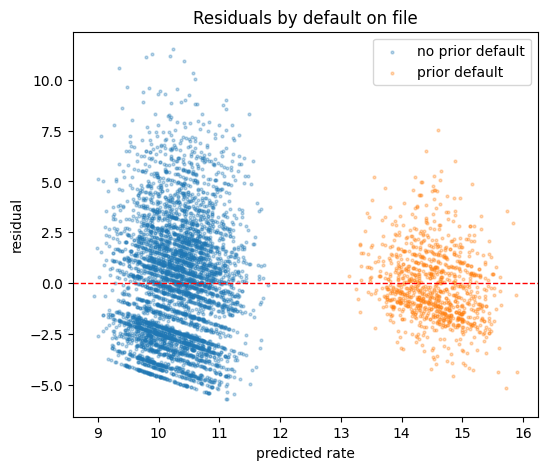

In [7]:
is_default = X_te["cb_person_default_on_file"] == "Y"

plt.figure(figsize=(6, 5))
plt.scatter(pred[~is_default], resid[~is_default], s=4, alpha=0.3, label="no prior default")
plt.scatter(pred[is_default],  resid[is_default],  s=4, alpha=0.3, label="prior default")
plt.axhline(0, color="r", ls="--", lw=1)
plt.xlabel("predicted rate"); plt.ylabel("residual"); plt.legend()
plt.title("Residuals by default on file")

As we can see the clouds form cleanly separated around the two answers for default on file. Confirming that the model predicts the rate around the prior default, with the other features acting as a small adjustments. So the datasets features don't set the rate. That information seems to be in the grade feature, which is likely computed from information not in the data set.

## Conclusion

Linear, Ridge and Lasso all land on the same $R^2 = 0.27$ (MAE = 2.21) against a baseline of 0.0 (MAE = 2.68). Since all three models reach the same scores, regularization has no effect, so there is no sign of overfitting from these models. The models all beat the baseline, but only drop the MAE by 0.47 points (about 17.5%), so they are only a small improvement over guessing the average. The models are better than nothing, but not really useful to predict the rates being set. A gradient-boosted model, included as a check for non-linear structure, reaches $R^2 = 0.30$ (MAE = 2.17). The small improvement suggests non-linearity exists, but not enough to change the picture and justify giving up the linear model's interpretability.

`cb_person_default_on_file` is the dominant feature, when excluding `loan_grade`. The models separate the predictions in two clusters, with `cb_person_default_on_file` setting the gap between them (+4.1 points for a prior default). After that `person_home_ownership` and `loan_amnt` act as small adjustments. The predictions cluster around 10% and 15%, while the actual rates range from 5% to 22%. Within each cluster, the residuals are centered around zero with no visible pattern, so the models capture each groups average rate, but not the spread within.

Concluding this, the models are bad predictors for the interest rates. This most likely stems from the information given by the dataset and not the model family. In the following notebook 03, I will look into how much information lies in the `loan_grade`.